# Cohort Second-Purchase Analysis

Measure the share of customers placing a second delivered order within 30, 60, and 90 days of their first delivered order, grouped by the month of that first purchase.

Each horizon uses only customers whose full follow-up window is observable before the dataset's last delivered-order purchase timestamp. Customers without enough follow-up are excluded from that horizon's denominator, rather than counted as non-returners. Customer identity uses `customer_unique_id`, since `customer_id` identifies an individual order's customer record.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Raw data directory not found: {DATA_DIR}")

orders = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    usecols=["order_id", "customer_id", "order_status", "order_purchase_timestamp"],
    parse_dates=["order_purchase_timestamp"],
)
customers = pd.read_csv(
    DATA_DIR / "olist_customers_dataset.csv",
    usecols=["customer_id", "customer_unique_id"],
)

print(f"Raw orders: {len(orders):,}")

Raw orders: 99,441


## 1. Define delivered purchases and customer timelines

A purchase is an order with `order_status == "delivered"`. Sort by timestamp and order ID to make the sequence deterministic, then retain each customer's first and second delivered-order timestamps.

In [2]:
delivered_orders = orders.loc[
    orders["order_status"].eq("delivered")
    & orders["order_purchase_timestamp"].notna()
].copy()

assert delivered_orders["order_id"].is_unique
assert customers["customer_id"].is_unique

customer_orders = delivered_orders.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
)
if customer_orders["customer_unique_id"].isna().any():
    raise ValueError("Some delivered orders are missing a stable customer ID")

customer_orders = customer_orders.sort_values(
    ["customer_unique_id", "order_purchase_timestamp", "order_id"]
).copy()
customer_orders["purchase_number"] = (
    customer_orders.groupby("customer_unique_id").cumcount() + 1
)

first_purchases = (
    customer_orders.loc[
        customer_orders["purchase_number"].eq(1),
        ["customer_unique_id", "order_purchase_timestamp"],
    ]
    .rename(columns={"order_purchase_timestamp": "first_purchase_at"})
)
second_purchases = (
    customer_orders.loc[
        customer_orders["purchase_number"].eq(2),
        ["customer_unique_id", "order_purchase_timestamp"],
    ]
    .rename(columns={"order_purchase_timestamp": "second_purchase_at"})
)

customer_timeline = first_purchases.merge(
    second_purchases,
    on="customer_unique_id",
    how="left",
    validate="one_to_one",
)
customer_timeline["cohort_month"] = (
    customer_timeline["first_purchase_at"].dt.to_period("M")
)

observation_end = delivered_orders["order_purchase_timestamp"].max()
print(f"Delivered orders: {len(delivered_orders):,}")
print(f"Customers with a delivered order: {len(customer_timeline):,}")
print(f"Last observable purchase timestamp: {observation_end}")

Delivered orders: 96,478
Customers with a delivered order: 93,358
Last observable purchase timestamp: 2018-08-29 15:00:37


## 2. Calculate follow-up-adjusted rates

A customer is eligible for horizon *H* only when `first_purchase_at + H days` is on or before the observation end. A return counts only if the second delivered order occurs on or before that exact deadline. The rates below are customer-level percentages, not percentages of orders.

In [3]:
horizons = (30, 60, 90)
cohort_months = pd.period_range(
    customer_timeline["cohort_month"].min(),
    customer_timeline["cohort_month"].max(),
    freq="M",
)
cohort_results = pd.DataFrame(index=cohort_months)
cohort_results.index.name = "cohort_month"

overall_rows = []
for days in horizons:
    deadline = customer_timeline["first_purchase_at"] + pd.to_timedelta(days, unit="D")
    eligible = customer_timeline.loc[deadline.le(observation_end)].copy()
    eligible["returned_within_horizon"] = (
        eligible["second_purchase_at"].notna()
        & eligible["second_purchase_at"].le(
            eligible["first_purchase_at"] + pd.to_timedelta(days, unit="D")
        )
    )

    by_cohort = eligible.groupby("cohort_month")["returned_within_horizon"].agg(
        eligible_customers="size",
        returning_customers="sum",
    )
    by_cohort["return_rate_pct"] = (
        by_cohort["returning_customers"] / by_cohort["eligible_customers"] * 100
    )
    by_cohort = by_cohort.reindex(cohort_months)
    cohort_results[f"eligible_{days}d"] = by_cohort["eligible_customers"]
    cohort_results[f"returned_{days}d"] = by_cohort["returning_customers"]
    cohort_results[f"rate_{days}d_pct"] = by_cohort["return_rate_pct"]

    overall_rows.append(
        {
            "horizon_days": days,
            "eligible_customers": len(eligible),
            "returning_customers": int(eligible["returned_within_horizon"].sum()),
            "return_rate_pct": eligible["returned_within_horizon"].mean() * 100,
        }
    )

cohort_results.index = cohort_results.index.astype(str)
overall_rates = pd.DataFrame(overall_rows).set_index("horizon_days")

print("Overall follow-up-adjusted second-purchase rates")
display(overall_rates.style.format({"return_rate_pct": "{:.2f}%"}))
print("Rates and denominator sizes by first delivered-order month")
display(
    cohort_results.style.format(
        {column: "{:.2f}%" for column in cohort_results if column.endswith("_pct")},
        na_rep="—",
    )
)

Overall follow-up-adjusted second-purchase rates


,eligible_customers,returning_customers,return_rate_pct
horizon_days,,,
30,86772,1373,1.58%
60,81203,1584,1.95%
90,75320,1714,2.28%


Rates and denominator sizes by first delivered-order month


,eligible_30d,returned_30d,rate_30d_pct,eligible_60d,returned_60d,rate_60d_pct,eligible_90d,returned_90d,rate_90d_pct
cohort_month,,,,,,,,,
2016-09,1.000000,0.000000,0.00%,1.000000,0.000000,0.00%,1.000000,0.000000,0.00%
2016-10,262.000000,3.000000,1.15%,262.000000,3.000000,1.15%,262.000000,3.000000,1.15%
2016-11,—,—,—,—,—,—,—,—,—
2016-12,1.000000,1.000000,100.00%,1.000000,1.000000,100.00%,1.000000,1.000000,100.00%
2017-01,717.000000,24.000000,3.35%,717.000000,26.000000,3.63%,717.000000,26.000000,3.63%
2017-02,1628.000000,23.000000,1.41%,1628.000000,25.000000,1.54%,1628.000000,28.000000,1.72%
2017-03,2503.000000,44.000000,1.76%,2503.000000,50.000000,2.00%,2503.000000,62.000000,2.48%
2017-04,2256.000000,34.000000,1.51%,2256.000000,42.000000,1.86%,2256.000000,48.000000,2.13%
2017-05,3451.000000,74.000000,2.14%,3451.000000,87.000000,2.52%,3451.000000,98.000000,2.84%


## 3. Compare cohorts visually

Missing values indicate cohorts without enough observation time for that horizon; they are intentionally not plotted as zero. Cohort rates can vary with customer mix and cohort size, so use the denominator columns when interpreting the chart.

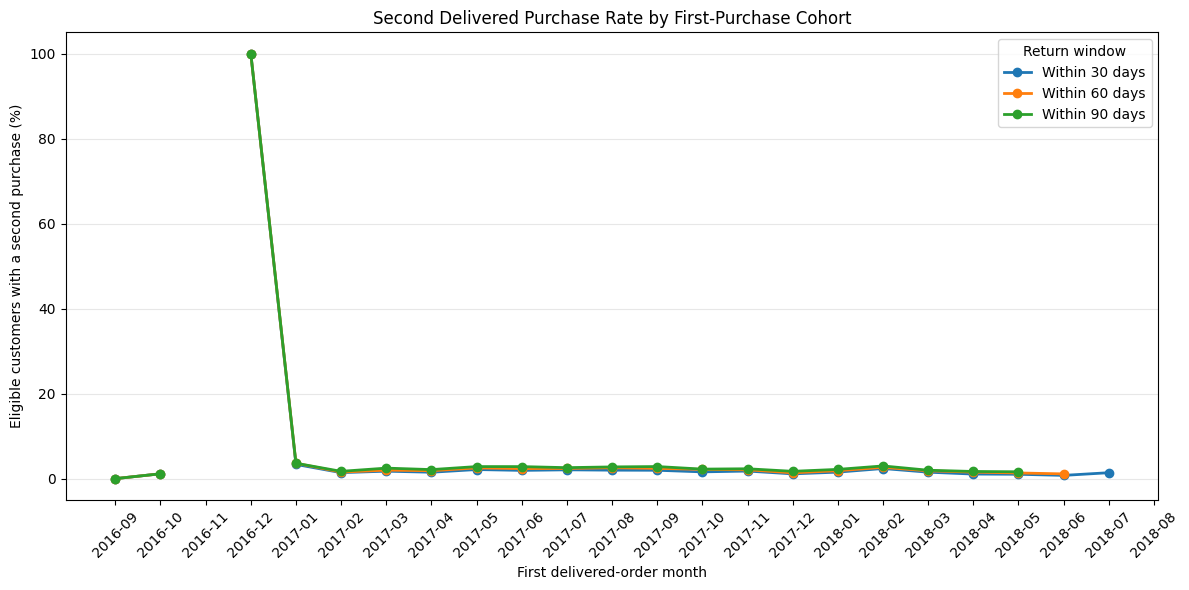

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))
for days in horizons:
    ax.plot(
        cohort_results.index,
        cohort_results[f"rate_{days}d_pct"],
        marker="o",
        linewidth=2,
        label=f"Within {days} days",
    )

ax.set_title("Second Delivered Purchase Rate by First-Purchase Cohort")
ax.set_xlabel("First delivered-order month")
ax.set_ylabel("Eligible customers with a second purchase (%)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Return window")
fig.tight_layout()
plt.show()

## Interpretation and limitations

- The observed overall rates are the proportion of customers with complete follow-up who made a second delivered purchase within each horizon. They are not lifetime retention or churn rates.
- Later cohorts have fewer eligible customers for longer horizons. The 90-day series therefore ends earlier than the 30-day series.
- The observation cutoff is the latest delivered-order **purchase timestamp** in the data. A delivered order's purchase date is used consistently for sequencing and follow-up.
- This is descriptive analysis of historical Olist data and does not establish why customers did or did not return.